<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 2 · Features</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Calendar features are the one kind of feature known for every future date: day of week, day of year and holiday flags depend only on the date, so they reach any horizon and cannot leak, provided the holiday calendar is the one known at the forecast origin. Their encoding decides what a model can learn. A tree can carve any seasonal shape out of a plain integer; a linear model given the same integer draws a straight line through the year, and needs one-hot columns, sine–cosine pairs or periodic splines instead. On a synthetic daily series with a weekly cycle, an annual season and Easter, a linear model's test error falls from $26.57$ t/day with integers to $7.33$ with splines, while a gradient-boosted model does best with integers ($7.56$) and worst with one-hot ($9.14$). Moving holidays need features of their own, and they break seasonal lags. When the season itself moves, days since it started is a better clock than the calendar, but only once the start has been observed. Afterwards you should be able to pick an encoding for your model, build holiday and season-clock features, and check each against the as-of rule.
:::

In [1]:
import sys
from pathlib import Path

import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dateutil.easter import easter
from feature_engine.creation import CyclicalFeatures
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import OneHotEncoder, SplineTransformer

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
colours = fallcolor.palette.discrete("default")

## Known for every future date

The features in [Lags and rolling windows](../lags-and-rolling-windows/lags_and_rolling_windows.ipynb) stop at the shortest usable lag, $h + d$ steps before the target. Calendar features are functions of the date alone, so they exist for any target date. Two edges need care: day of year jumps from $365$ to $1$ between neighbouring days, and some years have an ISO week $53$ (2020 did, as the lags module showed), which a model trained mostly on 52-week years sees rarely; a tree will usually lump it in with week $52$.

Under the as-of rule of [Leakage](../leakage/leakage.ipynb) calendar features are safe, except for the event calendar behind holiday flags: a one-off public holiday or a promotion week is known only once announced, so keep the calendar as it stood at each origin.

The data are synthetic daily volumes at a packhouse, 2016 to 2025: a 150-day season starting around day $100 \pm 10$ of the year, a weekday pattern, a run-up to Easter, and noise. There are five independent simulated series (seeds 0–4), averaged in every table.

::: {.callout-note collapse="true"}
## The formula

$$y_d = 60 + 80\, b_d + w_d + e_d + \varepsilon_d$$

where $y_d$ is the volume on day $d$ in tonnes; $b_d = \sin\big(\pi (j_d - s)/150\big)$ for $0 < j_d - s < 150$, else $0$, with $j_d$ the day of year and $s$ the start day, drawn each year from a normal distribution with mean $100$ and standard deviation $10$ days; $w_d$ is a weekday effect, from $-22$ t on Sundays to $+12$ t on Fridays; $e_d$ is an Easter effect rising from $+6$ t six days before Easter Sunday to $+36$ t on the Saturday, then $-25$ t on the Sunday; and $\varepsilon_d$ is autocorrelated noise in tonnes (coefficient $0.5$, shocks with standard deviation $5$ t).
:::

In [2]:
WEEKDAY = np.array([8, 4, 0, 4, 12, -6, -22])  # t/day, Monday to Sunday


def days_to_easter(dates):
    return (pd.to_datetime([easter(y) for y in dates.year]) - dates).days.to_numpy()


def simulate(seed, dates=pd.date_range("2016-01-01", "2025-12-31")):
    rng = np.random.default_rng(seed)
    yr = dates.year - dates.year[0]
    start = rng.normal(100, 10, yr.max() + 1)  # season start, day of year, one per year
    season_day = dates.dayofyear - start[yr]
    b = np.where((season_day > 0) & (season_day < 150), np.sin(np.pi * season_day / 150), 0)
    k = days_to_easter(dates)
    e = np.where((k >= 1) & (k <= 6), 6 * (7 - k), 0) - 25 * (k == 0)
    eps = np.zeros(len(dates))
    for t in range(1, len(dates)):
        eps[t] = 0.5 * eps[t - 1] + rng.normal(0, 5)
    mean = 60 + 80 * b + WEEKDAY[dates.dayofweek] + e
    return pd.DataFrame({"y": mean + eps, "mean": mean, "season_day": season_day}, index=dates)


panels = [simulate(seed) for seed in range(5)]
df = panels[0]
start = (df.index.dayofyear - df.season_day).groupby(df.index.year).first()
print("panel 0, season start by year (day of year):", start.round().astype(int).tolist())

panel 0, season start by year (day of year): [101, 99, 106, 101, 95, 104, 113, 109, 93, 87]


In the first series the season started between day $87$ and day $113$, a spread of $113 - 87 = 26$ days.

## Four ways to encode a cycle

A cyclic variable such as day of week (period $7$ days) or day of year ($365.25$ days) can enter a model as:

- **Integer**: one column, with 31 December and 1 January a year apart.
- **One-hot**: one 0/1 column per category; here day of year is cut into $52$ bins of about a week.
- **Sine and cosine**: the position as a point on a circle.
- **Periodic splines**: smooth overlapping bumps that wrap round from the end of the cycle to its start.

The sine–cosine pair is

$$x_{\sin} = \sin\frac{2\pi x}{P}, \qquad x_{\cos} = \cos\frac{2\pi x}{P}$$

where $x$ is the position in the cycle (day of week $0$ to $6$, or day of year minus one) and $P$ is the period in the same units; both are dimensionless, between $-1$ and $1$.

**If you use feature_engine, set the period yourself.** By default `CyclicalFeatures`, used in [Feature engineering with feature_engine](../forecast/1_feature_engineering.ipynb), takes $P$ from the column's largest value:

In [3]:
X = pd.DataFrame({"day_of_week": df.index.dayofweek, "day_of_year": df.index.dayofyear,
                  "week": np.minimum((df.index.dayofyear - 1) // 7, 51)})  # weeks 0 to 51
print("periods CyclicalFeatures takes by default:", CyclicalFeatures(variables=list(X)).fit(X).max_values_)

periods CyclicalFeatures takes by default: {'day_of_week': 6, 'day_of_year': 366, 'week': 51}


Weeks numbered $0$ to $51$ get $P = 51$, which glues week $51$ to week $0$, since $\sin(2\pi \cdot 51/51) = \sin 0$. Day of week gets $P = 6$, which puts Sunday on Monday. Day of year gets $366$ once training includes a leap year, a day too long in three years out of four, which barely matters. Pass `max_values={"week": 52, "day_of_week": 7}`.

**Why both sine and cosine.** On a 52-week cycle:

In [4]:
w = np.array([5, 21])
print("week:", w, " sin:", np.sin(2 * np.pi * w / 52).round(3), " cos:", np.cos(2 * np.pi * w / 52).round(3))

week: [ 5 21]  sin: [0.568 0.568]  cos: [ 0.823 -0.823]


Weeks $5$ and $21$ share a sine because $\sin\theta = \sin(\pi - \theta)$; the cosine tells them apart.

::: {.callout-note collapse="true"}
## More than one sine–cosine pair

Pairs at whole multiples of the base frequency, $\sin(2\pi k x/P)$ and $\cos(2\pi k x/P)$ for $k = 1, \dots, K$, form a Fourier series. With the maximum, $K = m/2$ for a period of $m$ steps, it gives the same fit as seasonal dummy variables[^1]. Choose $K$ by backtest.
:::

Periodic splines come from scikit-learn's `SplineTransformer` with `extrapolation="periodic"`: each basis function is a cubic bump over four of $n$ equal pieces of the cycle, and bumps that run off the end wrap into the start.

In [5]:
def encode(x, period, how, n=1):
    """A cyclic x in [0, period): one column, n one-hot bins, n sine-cosine pairs or n spline pieces."""
    x = np.asarray(x, dtype=float)[:, None]
    if how == "integer":
        return x
    if how == "one-hot":
        return OneHotEncoder(categories=[np.arange(n)], sparse_output=False).fit_transform(x * n // period)
    if how == "sin/cos":
        a = 2 * np.pi * x / period * np.arange(1, n + 1)
        return np.hstack([np.sin(a), np.cos(a)])
    knots = np.linspace(0, period, n + 1)[:, None]  # periodic cubic splines
    return SplineTransformer(knots=knots, extrapolation="periodic").fit_transform(x)


SETTINGS = {"integer": ("integer", 1, 1), "one-hot": ("one-hot", 7, 52), "sin/cos, 1 pair": ("sin/cos", 1, 1),
            "sin/cos, 3 pairs": ("sin/cos", 3, 3), "spline": ("spline", 7, 12)}  # (how, n for week, n for year)


def calendar_features(dates, setting="spline"):
    how, n_week, n_year = SETTINGS[setting]
    return np.hstack([encode(dates.dayofweek, 7, how, n_week), encode(dates.dayofyear - 1, 365.25, how, n_year)])

### Which model wants which

Each model trains on all years before a test year and forecasts all of it from calendar features alone; the table averages the mean absolute error (MAE) over test years 2023 to 2025. *Linear* is ridge regression with a tiny penalty ($\alpha = 0.001$) against collinear columns; *boosted* is scikit-learn's `HistGradientBoostingRegressor` with defaults. The floor is the error of the noise-free mean. *Columns* is weekday plus day-of-year columns: integer $1 + 1$, one-hot $7 + 52$, one pair $2 + 2$, three pairs $6 + 6$, spline $7 + 12$.

In [6]:
MODELS = {"linear": Ridge(alpha=1e-3), "boosted": HistGradientBoostingRegressor(random_state=0)}


def score(make_X, scored=lambda df: True):
    """Mean test MAE (t/day) over 5 panels and test years 2023-2025, each trained on all earlier years."""
    rows = []
    for df in panels:
        k = days_to_easter(df.index)
        for year in [2023, 2024, 2025]:
            X = make_X(df, year)
            train, test = df.index.year < year, (df.index.year == year) & scored(df)
            run_up = test & (k >= 0) & (k <= 6)
            for name, model in MODELS.items():
                Xm = X[name] if isinstance(X, dict) else X  # optionally a different X per model
                pred = model.fit(Xm[train], df.y[train]).predict(Xm)
                rows.append({"model": name, "all days": mean_absolute_error(df.y[test], pred[test]),
                             "Easter week": mean_absolute_error(df.y[run_up], pred[run_up]) if run_up.any() else np.nan})
    return pd.DataFrame(rows).groupby("model", sort=False).mean()


floor = np.mean([mean_absolute_error(df.y["2023":], df["mean"]["2023":]) for df in panels])
print(f"floor (MAE of the true mean): {floor:.2f} t/day")
table = pd.DataFrame({s: score(lambda df, y, s=s: calendar_features(df.index, s))["all days"] for s in SETTINGS}).T
table.insert(0, "columns", [calendar_features(df.index[:7], s).shape[1] for s in SETTINGS])
table.round(2)

floor (MAE of the true mean): 4.58 t/day


model,columns,linear,boosted
integer,2,26.57,7.56
one-hot,59,7.42,9.14
"sin/cos, 1 pair",4,15.97,7.70
"sin/cos, 3 pairs",12,7.47,7.82
spline,19,7.33,7.67


**Linear.** Integers score $26.57$ t/day: a straight line through the year (Figure 1). One sine–cosine pair scores $15.97$: one wave cannot stay flat for half the year and peak in the other. Three pairs ($7.47$), one-hot ($7.42$) and splines ($7.33$) are within $7.47 - 7.33 = 0.14$ of each other.

**Boosted.** Integers do best, $7.56$: a tree splits day of year into intervals, carving any season from the integer. One pair ($7.70$) and splines ($7.67$) add nothing. One-hot is worst, $9.14$: each split on a one-hot column peels off one week.

Linear wins here because the synthetic series is a sum of separate patterns. With lags and a tuned boosted model the ranking may change, the one-hot result especially, since it depends on `min_samples_leaf`; rerun the comparison with your own model.

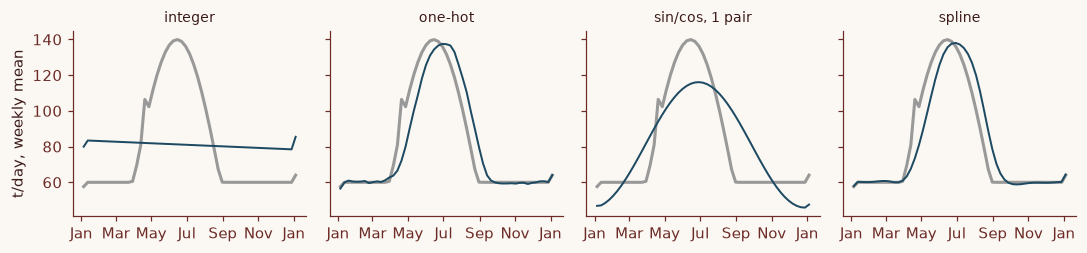

In [7]:
train, test = df.index.year < 2025, df.index.year == 2025
fig, axes = plt.subplots(1, 4, figsize=(10, 2.4), sharey=True)
for ax, s in zip(axes, ["integer", "one-hot", "sin/cos, 1 pair", "spline"]):
    X = calendar_features(df.index, s)
    pred = pd.Series(Ridge(alpha=1e-3).fit(X[train], df.y[train]).predict(X[test]), index=df.index[test])
    ax.plot(df["mean"][test].resample("W").mean(), color="0.6", lw=2)
    ax.plot(pred.resample("W").mean(), color=colours[0], lw=1.3)
    ax.set_title(s, fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_ylabel("t/day, weekly mean")
fig.tight_layout()
plt.show()

<strong>Figure 1 | What a linear model can draw with each encoding.</strong> Weekly means of 2025, first series: true mean (grey) and the linear model. One-hot and splines rise late because this season started on day $87$, the earliest of the ten.

## Holidays that move

Fixed-date holidays sit on a fixed day of year; moving ones do not:

In [8]:
e = [easter(y) for y in range(2000, 2100)]
lny = [min(d for d, n in holidays.SG(years=y).items() if n == "Chinese New Year") for y in range(2023, 2028)]
md = lambda d: (d.month, d.day)
print(f"Easter Sunday, 2000-2099: {min(e, key=md):%d %b %Y} to {max(e, key=md):%d %b %Y}")
print(f"Lunar New Year, 2023-2027: {min(lny, key=md):%d %b} to {max(lny, key=md):%d %b}")

Easter Sunday, 2000-2099: 23 Mar 2008 to 25 Apr 2038
Lunar New Year, 2023-2027: 22 Jan to 17 Feb


US Thanksgiving, the fourth Thursday of November, moves only between the 22nd and the 28th.

**They break seasonal lags.** Take Easter week to be the six days before Easter Sunday and the Sunday itself. `shift(364)` keeps the day of the week, but Easter has moved, so the lag misses the holiday where it is and copies it where it is not:

In [9]:
def snaive_errors(df):
    """Error of y[d - 364] in this year's Easter week, in last year's a year on, and on other days."""
    err = (df.y - df.y.shift(364)).abs()["2023":]
    k, k_last = days_to_easter(err.index), days_to_easter(err.index - pd.Timedelta(days=364))
    now, then = (k >= 0) & (k <= 6), (k_last >= 0) & (k_last <= 6)
    return pd.Series({"this year's Easter week": err[now].mean(), "a year after last year's": err[then & ~now].mean(),
                      "other days": err[~now & ~then].mean()})


pd.concat([snaive_errors(df) for df in panels], axis=1).mean(axis=1).round(2).rename("MAE (t/day)")

this year's Easter week     20.51
a year after last year's    25.96
other days                   9.53
Name: MAE (t/day), dtype: float64

The seasonal naive forecast misses by $20.51$ t/day in Easter week and $25.96$ a year after last year's, against $9.53$ elsewhere. In weekly data `shift(52)` does the same.

**Give the event its own feature**, encoded for the model: an **indicator** for Easter week; **days to Easter**, $0$ to $6$ in the window and $7$ outside, one integer column; or **one-hot days**, one column per day of the window. Error in Easter week, with spline calendar features:

In [10]:
def easter_features(dates, how):
    k = days_to_easter(dates)
    week = (k >= 0) & (k <= 6)  # six days before Easter Sunday, and the Sunday
    if how == "indicator":
        return week[:, None].astype(float)
    if how == "days to Easter":
        return np.where(week, k, 7)[:, None].astype(float)  # 7 = outside the window
    if how == "days to Easter, one-hot":
        return (k[:, None] == np.arange(7)).astype(float)
    return np.empty((len(dates), 0))


easter_results = {h: score(lambda df, y, h=h: np.hstack([calendar_features(df.index), easter_features(df.index, h)]))
                  for h in ["none", "indicator", "days to Easter", "days to Easter, one-hot"]}
pd.DataFrame({h: r["Easter week"] for h, r in easter_results.items()}).T.round(2)

model,linear,boosted
none,19.60,17.34
indicator,15.97,10.65
days to Easter,16.86,10.73
"days to Easter, one-hot",9.48,17.34


**Linear.** No holiday feature: $19.60$ t/day. The indicator, one average uplift for days whose true effect runs from $+36$ to $-25$ t, gets $15.97$; the integer distance, a straight line that cannot rise and then drop, $16.86$; one-hot days, $9.48$.

**Boosted.** The indicator ($10.65$) and the integer distance ($10.73$) do about equally well, probably because a tree can combine the flag with day of week: Easter Sunday is the only Sunday in the window. One-hot days score $17.34$, identical to no holiday feature: by default the model makes no leaf of fewer than $20$ rows, and each column is $1$ on only $7$ to $9$ training days.

With several moving holidays, give each its own indicator or distance feature and check each by the error in its own window.

## Season time, not calendar time

The synthetic start moved over $26$ days, and every calendar model is early or late by the difference (Figure 1). A better clock starts with the season: days since it started, or heat accumulated since then, as in [Chill hours and dormancy](../chill-hours-and-dormancy.qmd). But a start is known only once the season has begun. Three versions of days since the start, $j_d - s$, join the spline calendar and Easter features (through a spline for the linear model): the **true start** all year, an oracle; the **mean of past starts**, the best guess in January; and the **observed start**, scored only from the start onward.

In [11]:
def features(df, year=None, start=None, clock=True):
    """Spline calendar and Easter, plus days since season start if clock; for `year`, `start` replaces the true start."""
    s = df.season_day.to_numpy().copy()
    if year:
        s[df.index.year == year] = df.index.dayofyear[df.index.year == year] - start
    lin = [calendar_features(df.index), easter_features(df.index, "days to Easter, one-hot")]
    tree = [calendar_features(df.index), easter_features(df.index, "days to Easter")]
    if clock:  # the linear model needs a basis on this clock too
        lin, tree = lin + [SplineTransformer(n_knots=12).fit_transform(s[:, None])], tree + [s[:, None]]
    return {"linear": np.hstack(lin), "boosted": np.hstack(tree)}


def past_mean(df, year):
    starts = (df.index.dayofyear - df.season_day).groupby(df.index.year).first()
    return starts[starts.index < year].mean()


started = lambda df: df.season_day.to_numpy() >= 0  # on or after this year's start
pd.DataFrame({
    "calendar + Easter": score(lambda df, y: features(df, clock=False))["all days"],
    "+ true start (oracle)": score(lambda df, y: features(df))["all days"],
    "+ mean of past starts": score(lambda df, y: features(df, y, past_mean(df, y)))["all days"],
    "after start: calendar + Easter": score(lambda df, y: features(df, clock=False), started)["all days"],
    "after start: + observed start": score(lambda df, y: features(df), started)["all days"],
}).T.round(2)

model,linear,boosted
calendar + Easter,7.04,7.40
+ true start (oracle),4.81,5.23
+ mean of past starts,7.04,7.25
after start: calendar + Easter,7.62,8.00
after start: + observed start,4.78,5.28


The mean of past starts is only a shifted calendar, so it adds next to nothing: linear stays at $7.04$ t/day, boosted goes from $7.40$ to $7.25$. Once the start is observed, the clock recovers the oracle's gain on the remaining days: $7.62$ to $4.78$ (linear) and $8.00$ to $5.28$ (boosted), against the oracle's $4.81$ and $5.23$. This assumes the start is recognised on the day; in practice it is confirmed later.

In a berry pipeline the start could be the first-pick date or a degree-day threshold: forecast it from the chill and heat banked so far, use the forecast until the observed date exists, then swap.

## Key takeaways

- Calendar features are known for every future date; holiday flags only as far as the event calendar at the origin.
- Trees: plain integers. Linear models: periodic splines, one-hot or several sine–cosine pairs. Set the period by hand.
- Moving holidays need their own features; they break seasonal lags ($20.51/9.53 \approx 2.2$ times the error in Easter week).
- Days since the season started beats the date, from the day the start is known.

## References

[^1]: Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice* 3rd edn, section 7.4 (OTexts, 2021).

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/lags-and-rolling-windows/lags_and_rolling_windows.html"><span>Previous</span>Lags and rolling windows</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/baselines-first.html"><span>Next</span>Baselines first</a></div>
<!-- CURRICULUM_FOOTER_END -->